## Geoginah Ramatshe_26303686

# 2. Dataset Preprocessing and Feature Engineering

This notebook cleans the raw tables, creates customer-month snapshots, defines the future dormancy target, checks class imbalance, and splits the data chronologically into training, validation and test subsets.

## Why this preprocessing is used

- **Time-aware features:** predictor values must reflect information available on each snapshot date. Transactions and logins after the snapshot are not used as predictors.
- **Target definition:** among customers registered by the snapshot and active in the preceding 30 days, class `1` means no transaction in the following 90 days; class `0` means at least one transaction in that future period.
- **Leakage prevention:** client-supplied `active_investor`, `dormant_investor` and `days_since_last_activity` are not used as predictors. Whole-period funding roll-ups and current KYC status are also excluded later because they cannot be reconstructed historically.
- **Chronological splitting:** later periods are kept for validation and final testing. A 90-day gap between periods reduces overlap between future outcome windows.
- **Model preprocessing:** imputation, scaling and one-hot encoding are fitted within the model pipeline using training data only, preventing information from validation/test data leaking into preprocessing.

The resulting rows are **customer-month instances**, so the same customer may appear at multiple snapshot dates.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Raw CSV files are expected to be in the same folder as these notebooks.
BASE_DIR = Path.cwd()
RAW_FILES = {
    "profile": "table1_customer_profile.csv",
    "funding": "table2_account_funding.csv",
    "transactions": "table3_transaction_trading.csv",
    "engagement": "table4_platform_engagement.csv",
}

def safe_date(series):
    return pd.to_datetime(series, errors="coerce")

missing_files = [name for name in RAW_FILES.values() if not (BASE_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        "Could not find these CSV files in the notebook's current folder: "
        + ", ".join(missing_files)
        + ". Place the CSV files beside the notebooks or update BASE_DIR.")

## 1. Clean and inspect the raw tables

In [2]:
# Load the raw tables
profile_raw = pd.read_csv(BASE_DIR / RAW_FILES["profile"])
funding_raw = pd.read_csv(BASE_DIR / RAW_FILES["funding"])
transaction_raw = pd.read_csv(BASE_DIR / RAW_FILES["transactions"])
engagement_raw = pd.read_csv(BASE_DIR / RAW_FILES["engagement"])

# Deduplicate profile/funding records and parse dates.
profile = profile_raw.drop_duplicates().drop_duplicates(subset=["customer_id"]).copy()
profile["registration_dt"] = safe_date(profile["registration_date"])
profile["age"] = pd.to_numeric(profile["age"], errors="coerce")
profile.loc[(profile["age"] < 18) | (profile["age"] > 100), "age"] = np.nan

cat_profile = ["gender", "province", "occupation", "monthly_income_band", "investment_experience"]
for col in cat_profile:
    profile[col] = (profile[col].astype("string").str.strip().str.lower().replace({"": pd.NA, "nan": pd.NA, "none": pd.NA}))

funding = funding_raw.drop_duplicates(subset=["customer_id"]).copy()
funding["first_deposit_dt"] = safe_date(funding["first_deposit_date"])
funding["first_deposit_amount"] = pd.to_numeric(funding["first_deposit_amount"], errors="coerce")

# Only use the event columns needed for time-based features and the target.
transaction_columns_allowed = [
    "customer_id", "transaction_datetime", "asset_type", "asset_name", "transaction_value"
]
transactions = transaction_raw[transaction_columns_allowed].copy()
transactions["transaction_dt"] = safe_date(transactions["transaction_datetime"])
transactions["transaction_value"] = pd.to_numeric(transactions["transaction_value"], errors="coerce")
transactions = transactions.dropna(subset=["customer_id", "transaction_dt"]).copy()
transactions = transactions.drop_duplicates(
    subset=["customer_id", "transaction_dt", "asset_type", "asset_name", "transaction_value"])

engagement = engagement_raw.copy()
engagement["login_dt"] = safe_date(engagement["login_date"])
engagement["session_duration"] = pd.to_numeric(engagement["session_duration"], errors="coerce")
engagement = engagement.dropna(subset=["customer_id", "login_dt"]).copy()
engagement["device_clean"] = (engagement["mobile_or_web"].astype("string").str.strip().str.lower())

assert not {"active_investor", "dormant_investor", "days_since_last_activity"}.intersection(transactions.columns)

quality_summary = pd.DataFrame([
    {"check": "Unique customer profiles after deduplication", "value": profile["customer_id"].nunique()},
    {"check": "Valid dated transaction events retained", "value": len(transactions)},
    {"check": "Transaction rows excluded for missing date", "value": int(safe_date(transaction_raw["transaction_datetime"]).isna().sum())},
    {"check": "Unique customers with valid transaction events", "value": transactions["customer_id"].nunique()},
    {"check": "Engagement/login records retained", "value": len(engagement)},
    {"check": "Unique customers with engagement records", "value": engagement["customer_id"].nunique()},
    {"check": "Missing session duration values", "value": int(engagement["session_duration"].isna().sum())},
])
display(quality_summary)

,check,value
0,Unique customer profiles after deduplication,5417
1,Valid dated transaction events retained,16282
2,Transaction rows excluded for missing date,421
3,Unique customers with valid transaction events,2023
4,Engagement/login records retained,57529
5,Unique customers with engagement records,4617
6,Missing session duration values,737


## 2. Build customer-month snapshots and target labels

In [3]:
def aggregate_transactions(events, prefix):
    """Create transaction features using only the passed time window."""
    columns = ["customer_id", f"{prefix}_tx_count", f"{prefix}_total_value",
               f"{prefix}_avg_value", f"{prefix}_asset_type_count",
               f"{prefix}_asset_name_count", f"{prefix}_active_days"]
    if events.empty:
        return pd.DataFrame(columns=columns)
    work = events.copy()
    work["_asset_type"] = work["asset_type"].astype("string").str.strip().str.lower().fillna("unknown")
    work["_asset_name"] = work["asset_name"].astype("string").str.strip().str.lower().fillna("unknown")
    work["_active_day"] = work["transaction_dt"].dt.normalize()
    return work.groupby("customer_id").agg(**{
        f"{prefix}_tx_count": ("transaction_dt", "size"),
        f"{prefix}_total_value": ("transaction_value", "sum"),
        f"{prefix}_avg_value": ("transaction_value", "mean"),
        f"{prefix}_asset_type_count": ("_asset_type", "nunique"),
        f"{prefix}_asset_name_count": ("_asset_name", "nunique"),
        f"{prefix}_active_days": ("_active_day", "nunique"),}).reset_index()


def aggregate_logins(events, prefix):
    """Create engagement features from login/session records in a past window."""
    columns = ["customer_id", f"{prefix}_login_records", f"{prefix}_login_days",
               f"{prefix}_avg_session_duration", f"{prefix}_mobile_share"]
    if events.empty:
        return pd.DataFrame(columns=columns)
    work = events.copy()
    work["_login_day"] = work["login_dt"].dt.normalize()
    return work.groupby("customer_id").agg(**{
        f"{prefix}_login_records": ("login_dt", "size"),
        f"{prefix}_login_days": ("_login_day", "nunique"),
        f"{prefix}_avg_session_duration": ("session_duration", "mean"),
        f"{prefix}_mobile_share": ("device_clean", lambda x: (x == "mobile").mean()),}).reset_index()


def create_snapshot(customers, funding_data, tx, logins, cutoff, recent_days=30, future_days=90):
    """Create customer-month instances using only information available by cutoff."""
    cutoff = pd.Timestamp(cutoff)
    recent_start = cutoff - pd.Timedelta(days=recent_days)
    prior_start = cutoff - pd.Timedelta(days=90)
    future_end = cutoff + pd.Timedelta(days=future_days)

    if tx.empty or future_end > tx["transaction_dt"].max().normalize():
        raise ValueError(
            f"The full future window is not observable for {cutoff.date()}. "
            "Choose snapshot dates with at least 90 days of subsequent transaction coverage.")

    tx_history = tx[tx["transaction_dt"] <= cutoff].merge(
        customers[["customer_id", "registration_dt"]], on="customer_id", how="left"
    )
    tx_history = tx_history[
        tx_history["transaction_dt"] >= tx_history["registration_dt"]
    ].drop(columns=["registration_dt"])

    tx_recent = tx_history[tx_history["transaction_dt"] > recent_start]
    tx_prior = tx_history[
        (tx_history["transaction_dt"] > prior_start)
        & (tx_history["transaction_dt"] <= recent_start)
    ]

    # Future transactions are used only to construct the target.
    tx_future = tx[
        (tx["transaction_dt"] > cutoff) & (tx["transaction_dt"] <= future_end)
    ]
    future_active_ids = set(tx_future["customer_id"].unique())
    recently_active_ids = set(tx_recent["customer_id"].unique())

    eligible = customers[customers["registration_dt"] <= cutoff].copy()
    eligible = eligible[eligible["customer_id"].isin(recently_active_ids)].copy()
    if eligible.empty:
        return pd.DataFrame()

    eligible["snapshot_date"] = cutoff
    eligible["account_tenure_days"] = (cutoff - eligible["registration_dt"]).dt.days
    eligible = eligible.drop(columns=["registration_dt"])

    deposit_feats = funding_data[
        ["customer_id", "first_deposit_dt", "first_deposit_amount"]
    ].copy()
    out = eligible.merge(deposit_feats, on="customer_id", how="left")
    out["has_first_deposit_by_snapshot"] = (
        out["first_deposit_dt"].notna() & (out["first_deposit_dt"] <= cutoff)
    ).astype(int)
    out["days_since_first_deposit_at_snapshot"] = np.where(
        out["has_first_deposit_by_snapshot"].eq(1),
        (cutoff - out["first_deposit_dt"]).dt.days, np.nan
    )
    out["first_deposit_amount_asof"] = np.where(
        out["has_first_deposit_by_snapshot"].eq(1),
        out["first_deposit_amount"], np.nan
    )
    out = out.drop(columns=["first_deposit_dt", "first_deposit_amount"])

    hist_features = aggregate_transactions(tx_history, "history")
    hist_dates = tx_history.groupby("customer_id").agg(
        first_tx_at_snapshot=("transaction_dt", "min"),
        last_tx_at_snapshot=("transaction_dt", "max"),
    ).reset_index()
    hist_features = hist_features.merge(hist_dates, on="customer_id", how="left")
    hist_features["days_since_last_transaction_at_snapshot"] = (
        cutoff - hist_features["last_tx_at_snapshot"]
    ).dt.days
    hist_features["transaction_history_days"] = (
        cutoff - hist_features["first_tx_at_snapshot"]
    ).dt.days.clip(lower=0)
    hist_features["history_tx_per_day"] = (
        hist_features["history_tx_count"]
        / hist_features["transaction_history_days"].clip(lower=1)
    )
    hist_features = hist_features.drop(
        columns=["first_tx_at_snapshot", "last_tx_at_snapshot"]
    )

    out = out.merge(hist_features, on="customer_id", how="left")
    out = out.merge(aggregate_transactions(tx_recent, "recent30"), on="customer_id", how="left")
    out = out.merge(aggregate_transactions(tx_prior, "prior60"), on="customer_id", how="left")

    login_history = logins[logins["login_dt"] <= cutoff].merge(
        customers[["customer_id", "registration_dt"]], on="customer_id", how="left"
    )
    login_history = login_history[
        login_history["login_dt"] >= login_history["registration_dt"]
    ].drop(columns=["registration_dt"])
    login30 = login_history[login_history["login_dt"] > recent_start]
    login90 = login_history[login_history["login_dt"] > prior_start]

    login_features = aggregate_logins(login_history, "history")
    if not login_history.empty:
        last_login = login_history.groupby("customer_id")["login_dt"].max().rename("last_login_at_snapshot").reset_index()
        last_login["days_since_last_login_at_snapshot"] = (cutoff - last_login["last_login_at_snapshot"]).dt.days
        login_features = login_features.merge(last_login[["customer_id", "days_since_last_login_at_snapshot"]],
            on="customer_id", how="left")

    out = out.merge(login_features, on="customer_id", how="left")
    out = out.merge(aggregate_logins(login30, "login30"), on="customer_id", how="left")
    out = out.merge(aggregate_logins(login90, "login90"), on="customer_id", how="left")

    out["dormancy_target"] = (~out["customer_id"].isin(future_active_ids)).astype(int)
    return out

snapshot_dates = list(pd.date_range("2024-09-30", "2026-05-31", freq="ME"))
latest_transaction_date = transactions["transaction_dt"].max()
print(f"Last valid transaction date: {latest_transaction_date}")
print(f"Snapshot dates planned: {len(snapshot_dates)}")
assert all(
    d + pd.Timedelta(days=90) <= latest_transaction_date.normalize()
    for d in snapshot_dates
), "At least one snapshot lacks the complete 90-day future target window."

snapshot_frames = []
for snap in snapshot_dates:
    frame = create_snapshot(customers=profile, funding_data=funding, tx=transactions,
        logins=engagement, cutoff=snap, recent_days=30, future_days=90)
    
    if not frame.empty:
        snapshot_frames.append(frame)

if not snapshot_frames:
    raise ValueError("No eligible customer-month snapshots were created. Check dates and eligibility rules.")

model_data = pd.concat(snapshot_frames, ignore_index=True)
for col in model_data.select_dtypes(include=["object", "string", "category"]).columns:
    model_data[col] = model_data[col].astype(object).where(model_data[col].notna(), np.nan)

print(f"Engineered dataset: {len(model_data):,} customer-month instances")
print(f"Distinct customers represented: {model_data['customer_id'].nunique():,}")
print(f"Snapshot dates represented: {model_data['snapshot_date'].nunique()}")

Last valid transaction date: 2026-09-07 19:02:04
Snapshot dates planned: 21
Engineered dataset: 9,334 customer-month instances
Distinct customers represented: 1,850
Snapshot dates represented: 21


## 3. Target classes and class imbalance

,class_value,class_name,instances,proportion
0,0,Remains active,7714,0.826441
1,1,Dormant within next 90 days,1620,0.173559


Overall dormant class proportion: 17.4%
Class ratio (active:dormant): 4.76:1


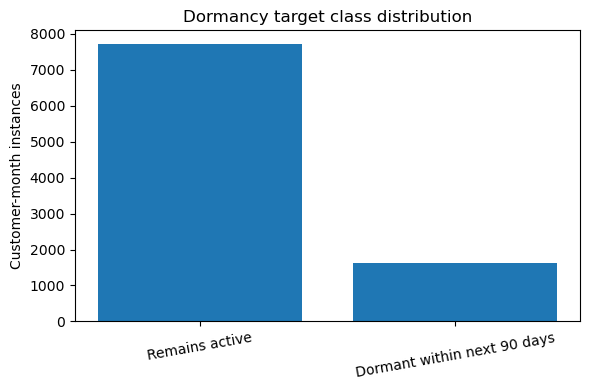

In [4]:
target_counts = model_data["dormancy_target"].value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame({
    "class_value": [0, 1],
    "class_name": ["Remains active", "Dormant within next 90 days"],
    "instances": [int(target_counts.loc[0]), int(target_counts.loc[1])],
    "proportion": [float(target_counts.loc[0] / len(model_data)),
                   float(target_counts.loc[1] / len(model_data)) ],
})

display(target_summary)
print(f"Overall dormant class proportion: {model_data['dormancy_target'].mean():.1%}")
print(f"Class ratio (active:dormant): {target_counts.loc[0] / max(target_counts.loc[1], 1):.2f}:1")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(target_summary["class_name"], target_summary["instances"])
ax.set_title("Dormancy target class distribution")
ax.set_ylabel("Customer-month instances")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
plt.show()

## 4. Chronological train, validation and test split

- **Training:** snapshots through 31 March 2025.
- **Validation:** 30 June to 31 October 2025.
- **Test:** 31 January to 31 May 2026.
- April–May 2025 and November–December 2025 are excluded as 90-day outcome-window gaps.

Validation is used for selecting model settings. The later test subset is held back for final evaluation.

,subset,instances,distinct_customers,dormant_count,active_count,dormant_proportion,first_snapshot,last_snapshot
0,Train,2138,668,171,1967,0.079981,2024-09-30,2025-03-31
1,Validation,2553,1053,473,2080,0.185272,2025-06-30,2025-10-31
2,Test,2636,1120,633,2003,0.240137,2026-01-31,2026-05-31


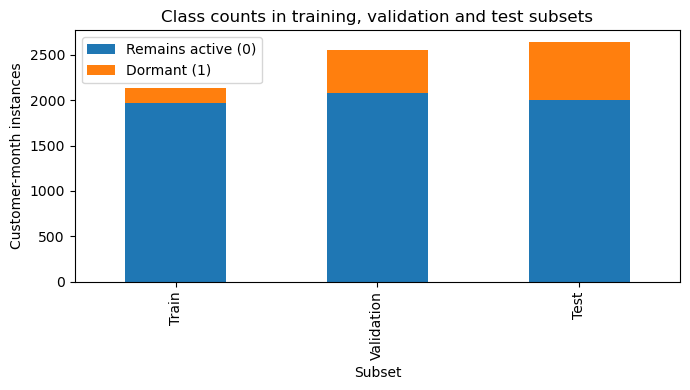

In [6]:
train_data = model_data[model_data["snapshot_date"] <= pd.Timestamp("2025-03-31")].copy()
validation_data = model_data[
    (model_data["snapshot_date"] >= pd.Timestamp("2025-06-30"))
    & (model_data["snapshot_date"] <= pd.Timestamp("2025-10-31"))].copy()

test_data = model_data[
    (model_data["snapshot_date"] >= pd.Timestamp("2026-01-31"))
    & (model_data["snapshot_date"] <= pd.Timestamp("2026-05-31"))].copy()

split_summary = pd.DataFrame([
    {
        "subset": name, "instances": len(data),
        "distinct_customers": data["customer_id"].nunique(),
        "dormant_count": int(data["dormancy_target"].sum()),
        "active_count": int((data["dormancy_target"] == 0).sum()),
        "dormant_proportion": float(data["dormancy_target"].mean()) if len(data) else np.nan,
        "first_snapshot": data["snapshot_date"].min(),
        "last_snapshot": data["snapshot_date"].max(),
    }
    for name, data in [("Train", train_data), ("Validation", validation_data), ("Test", test_data)]
])

display(split_summary)
if train_data.empty or validation_data.empty or test_data.empty:
    raise ValueError("One or more chronological splits are empty. Check the dataset date coverage and snapshot rules.")

fig, ax = plt.subplots(figsize=(7, 4))
split_summary.set_index("subset")[["active_count", "dormant_count"]].plot(
    kind="bar", stacked=True, ax=ax)

ax.set_title("Class counts in training, validation and test subsets")
ax.set_ylabel("Customer-month instances")
ax.set_xlabel("Subset")
ax.legend(["Remains active (0)", "Dormant (1)"])
fig.tight_layout()
plt.show()

## 5. Save prepared datasets for the next notebooks

The training, validation and test notebooks will load these files rather than repeat feature engineering. 

In [7]:
PROCESSED_DIR = BASE_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

model_data.to_csv(PROCESSED_DIR / "dormancy_snapshot_dataset.csv", index=False)
train_data.to_csv(PROCESSED_DIR / "train_data.csv", index=False)
validation_data.to_csv(PROCESSED_DIR / "validation_data.csv", index=False)
test_data.to_csv(PROCESSED_DIR / "test_data.csv", index=False)
target_summary.to_csv(PROCESSED_DIR / "target_class_summary.csv", index=False)
split_summary.to_csv(PROCESSED_DIR / "split_summary.csv", index=False)

print("Saved model dataset and split files to:", PROCESSED_DIR.resolve())

Saved model dataset and split files to: C:\Users\HP\Documents\4.CAPSTONE Project\SS3 final\retail_investor_dormancy_notebooks\processed
